# Midterm Project: Comparing Three NLP Models

**Course:** AAI 6620 Applied NLP · **Author:** Fengbo Lyu

**Task:** character-level language modelling — *given previous text, predict the next character.*
Three architectures are trained and compared on the **same dataset** and the **same task**:

1. **Bigram** — predicts the next char from the current char only.
2. **LSTM** (non-transformer) — a recurrent network that carries a hidden state over the sequence.
3. **Small Transformer** — token + positional embeddings, masked multi-head self-attention, feed-forward layers.

The goal is not maximum performance but to understand *how the architectures differ and why attention helps.*

In [1]:
import torch
import torch.nn as nn
from torch.nn import functional as F
import time
import pandas as pd
import matplotlib.pyplot as plt

torch.manual_seed(1337)
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print("Using device:", device)

# ---- shared hyperparameters (small enough for a laptop / Colab CPU) ----
block_size = 64     # context length used by the LSTM and Transformer
batch_size = 32
eval_iters = 50     # batches averaged when estimating loss

Using device: cpu


## Section 1 — Data

We use a public-domain Shakespeare corpus (character level). The same encoding, train/validation
split, and batching are reused by all three models so the comparison is fair.

In [2]:
with open('data/input.txt', 'r', encoding='utf-8') as f:
    text = f.read()

chars = sorted(set(text))
vocab_size = len(chars)
stoi = {c: i for i, c in enumerate(chars)}
itos = {i: c for i, c in enumerate(chars)}
encode = lambda s: [stoi[c] for c in s]
decode = lambda l: ''.join(itos[i] for i in l)

data = torch.tensor(encode(text), dtype=torch.long)
n = int(0.9 * len(data))
train_data, val_data = data[:n], data[n:]

print(f"Corpus characters : {len(text):,}")
print(f"Vocabulary size   : {vocab_size}")
print(f"Train / Val split : {len(train_data):,} / {len(val_data):,}")


def get_batch(split, bsize=batch_size, bptt=block_size):
    """Sample a mini-batch of (context, next-char) pairs."""
    d = train_data if split == 'train' else val_data
    ix = torch.randint(len(d) - bptt - 1, (bsize,))
    x = torch.stack([d[i:i + bptt] for i in ix])
    y = torch.stack([d[i + 1:i + bptt + 1] for i in ix])
    return x.to(device), y.to(device)


@torch.no_grad()
def estimate_loss(model, bptt=block_size):
    """Average train/val loss over several batches (less noisy than one batch)."""
    out = {}
    model.eval()
    for split in ['train', 'val']:
        losses = torch.zeros(eval_iters)
        for k in range(eval_iters):
            X, Y = get_batch(split, bptt=bptt)
            _, loss = model(X, Y)
            losses[k] = loss.item()
        out[split] = losses.mean().item()
    model.train()
    return out


def train_model(model, max_iters, lr, eval_interval, label):
    """Train a model with AdamW; return (loss_history, wall_clock_seconds)."""
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr)
    history = []
    t0 = time.time()
    for it in range(max_iters + 1):
        if it % eval_interval == 0 or it == max_iters:
            losses = estimate_loss(model)
            history.append((it, losses['train'], losses['val']))
            print(f"[{label}] step {it:4d} | train {losses['train']:.4f} | val {losses['val']:.4f}")
        xb, yb = get_batch('train')
        _, loss = model(xb, yb)
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        optimizer.step()
    return history, time.time() - t0


@torch.no_grad()
def generate(model, max_new_tokens=400, bptt=block_size):
    """Autoregressively sample text from a trained model."""
    model.eval()
    idx = torch.zeros((1, 1), dtype=torch.long, device=device)
    for _ in range(max_new_tokens):
        idx_cond = idx[:, -bptt:]
        logits, _ = model(idx_cond)
        logits = logits[:, -1, :]
        probs = F.softmax(logits, dim=-1)
        nxt = torch.multinomial(probs, num_samples=1)
        idx = torch.cat([idx, nxt], dim=1)
    model.train()
    return decode(idx[0].tolist())


def count_params(model):
    return sum(p.numel() for p in model.parameters())

Corpus characters : 249,959
Vocabulary size   : 69
Train / Val split : 224,963 / 24,996


## Section 2 — Model 1: Bigram

The bigram model is a single lookup table of shape `(vocab_size, vocab_size)`: row *i* is the
probability distribution over the next character given that the **current** character is *i*.

- **What it uses:** only the single most recent character.
- **What it ignores:** everything before that character — all longer context.
- **Why its language understanding is limited:** with a one-character memory it cannot model words,
  grammar, or any dependency longer than two characters, so its predictions are essentially local
  character statistics.

In [3]:
class BigramLanguageModel(nn.Module):
    """Predicts the next token purely from the current token (a lookup table of logits)."""

    def __init__(self, vocab_size):
        super().__init__()
        self.token_emb = nn.Embedding(vocab_size, vocab_size)

    def forward(self, idx, targets=None):
        logits = self.token_emb(idx)  # (B, T, vocab_size)
        loss = None
        if targets is not None:
            B, T, C = logits.shape
            loss = F.cross_entropy(logits.view(B * T, C), targets.view(B * T))
        return logits, loss


bigram_model = BigramLanguageModel(vocab_size).to(device)
bigram_params = count_params(bigram_model)
print(f"Bigram parameters: {bigram_params:,}")

bigram_hist, bigram_time = train_model(
    bigram_model, max_iters=3000, lr=1e-2, eval_interval=500, label="Bigram")
print(f"\nBigram training time: {bigram_time:.1f}s")

bigram_sample = generate(bigram_model, max_new_tokens=400)
print("\n--- Bigram generated sample ---")
print(bigram_sample)

Bigram parameters: 4,761


[Bigram] step    0 | train 4.7515 | val 4.7323


[Bigram] step  500 | train 2.5344 | val 2.5458


[Bigram] step 1000 | train 2.4803 | val 2.4902


[Bigram] step 1500 | train 2.4648 | val 2.4861


[Bigram] step 2000 | train 2.4591 | val 2.4873


[Bigram] step 2500 | train 2.4547 | val 2.4775


[Bigram] step 3000 | train 2.4589 | val 2.4740

Bigram training time: 3.4s

--- Bigram generated sample ---
	Gressthy thalethopre ma
Laver-jeng aunteill halaron wis tllke andal, meas the or
Wh je ere? f we n wandow h intisttanss hof bue Shir astee y aven.
I mf cal T, me sulourd bay houtheachosargaule he Ton's inour Wh ppr at t ofor orily Hak, aldmindd: Kns ity ff s! pe tr iscken ientus amewacoou bowh hela ris eren? isushe Mo athy.
GNe, mor Pe wok'sonkilllofed t
SExed ct aves d thnrd cetrgdl, unou, sean I


## Section 3 — Model 2: LSTM (non-transformer)

The LSTM embeds each character, then processes the sequence one step at a time while maintaining a
**hidden state** (and cell state) that summarises everything seen so far.

- **More context than bigram:** instead of a one-character memory, the recurrent hidden state can, in
  principle, carry information from many previous characters, so it can learn words and short phrases.
- **What it improves:** far more coherent spelling and local grammar than the bigram.
- **Why it still struggles with long dependencies:** information must survive being passed through
  every time step; over long distances the signal is diluted (the vanishing-gradient problem that
  gating only partly fixes), and there is no direct connection between distant positions.

In [4]:
class LSTMModel(nn.Module):
    """Embedding -> LSTM -> linear head. A recurrent (non-attention) language model."""

    def __init__(self, vocab_size, n_embd=96, hidden=192, n_layers=1):
        super().__init__()
        self.token_emb = nn.Embedding(vocab_size, n_embd)
        self.lstm = nn.LSTM(n_embd, hidden, num_layers=n_layers, batch_first=True)
        self.head = nn.Linear(hidden, vocab_size)

    def forward(self, idx, targets=None):
        x = self.token_emb(idx)       # (B, T, n_embd)
        out, _ = self.lstm(x)         # (B, T, hidden)
        logits = self.head(out)       # (B, T, vocab_size)
        loss = None
        if targets is not None:
            B, T, C = logits.shape
            loss = F.cross_entropy(logits.view(B * T, C), targets.view(B * T))
        return logits, loss


lstm_model = LSTMModel(vocab_size).to(device)
lstm_params = count_params(lstm_model)
print(f"LSTM parameters: {lstm_params:,}")

lstm_hist, lstm_time = train_model(
    lstm_model, max_iters=1500, lr=3e-3, eval_interval=300, label="LSTM")
print(f"\nLSTM training time: {lstm_time:.1f}s")

lstm_sample = generate(lstm_model, max_new_tokens=400)
print("\n--- LSTM generated sample ---")
print(lstm_sample)

LSTM parameters: 242,661


[LSTM] step    0 | train 4.2345 | val 4.2344


[LSTM] step  300 | train 1.8246 | val 1.8873


[LSTM] step  600 | train 1.6505 | val 1.7402


[LSTM] step  900 | train 1.5596 | val 1.6832


[LSTM] step 1200 | train 1.4880 | val 1.6481


[LSTM] step 1500 | train 1.4341 | val 1.6436

LSTM training time: 108.7s



--- LSTM generated sample ---
	I, fair, whonem your love
Therefore, no look us loth? 'Not here. The English Sever lieve alcheap'd
These stolding and sounds! Blunt, thou still it is not, where it I all
groudge upon on prescue or liestudg
its on as remanning last towgue rebel,
Did drawn'd these Sarlish did name of Talbot, bair
Thus vilit om majesty to, if the Boringgroas! but yet we and four again
To go, my lord, and bent such a'


## Section 4 — Model 3: Small Transformer

A decoder-only transformer. Each position is given a **token embedding** plus a **positional
embedding**, then passed through blocks of **masked multi-head self-attention** and a **feed-forward
layer** (with residual connections and layer norm), ending in an **output projection** to the vocab.

Self-attention lets **every position look directly at every earlier position** in one step — there is
no information bottleneck as in the LSTM — which is what lets transformers capture longer-range
structure efficiently.

In [5]:
n_embd = 96
n_head = 4
n_layer = 2
dropout = 0.1


class Head(nn.Module):
    """One head of masked self-attention."""

    def __init__(self, head_size):
        super().__init__()
        self.key = nn.Linear(n_embd, head_size, bias=False)
        self.query = nn.Linear(n_embd, head_size, bias=False)
        self.value = nn.Linear(n_embd, head_size, bias=False)
        self.register_buffer('tril', torch.tril(torch.ones(block_size, block_size)))
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        B, T, C = x.shape
        k = self.key(x)
        q = self.query(x)
        wei = q @ k.transpose(-2, -1) * k.shape[-1] ** -0.5     # affinities
        wei = wei.masked_fill(self.tril[:T, :T] == 0, float('-inf'))  # causal mask
        wei = F.softmax(wei, dim=-1)
        wei = self.dropout(wei)
        return wei @ self.value(x)


class MultiHeadAttention(nn.Module):
    def __init__(self, n_head, head_size):
        super().__init__()
        self.heads = nn.ModuleList([Head(head_size) for _ in range(n_head)])
        self.proj = nn.Linear(n_embd, n_embd)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        out = torch.cat([h(x) for h in self.heads], dim=-1)
        return self.dropout(self.proj(out))


class FeedForward(nn.Module):
    def __init__(self, n_embd):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_embd, 4 * n_embd), nn.ReLU(),
            nn.Linear(4 * n_embd, n_embd), nn.Dropout(dropout))

    def forward(self, x):
        return self.net(x)


class Block(nn.Module):
    """Transformer block: self-attention + feed-forward, both with residual + layer norm."""

    def __init__(self, n_embd, n_head):
        super().__init__()
        self.sa = MultiHeadAttention(n_head, n_embd // n_head)
        self.ff = FeedForward(n_embd)
        self.ln1 = nn.LayerNorm(n_embd)
        self.ln2 = nn.LayerNorm(n_embd)

    def forward(self, x):
        x = x + self.sa(self.ln1(x))
        x = x + self.ff(self.ln2(x))
        return x


class TransformerModel(nn.Module):
    def __init__(self, vocab_size):
        super().__init__()
        self.token_emb = nn.Embedding(vocab_size, n_embd)
        self.pos_emb = nn.Embedding(block_size, n_embd)
        self.blocks = nn.Sequential(*[Block(n_embd, n_head) for _ in range(n_layer)])
        self.ln_f = nn.LayerNorm(n_embd)
        self.head = nn.Linear(n_embd, vocab_size)

    def forward(self, idx, targets=None):
        B, T = idx.shape
        tok = self.token_emb(idx)
        pos = self.pos_emb(torch.arange(T, device=idx.device))
        x = tok + pos
        x = self.blocks(x)
        x = self.ln_f(x)
        logits = self.head(x)
        loss = None
        if targets is not None:
            B, T, C = logits.shape
            loss = F.cross_entropy(logits.view(B * T, C), targets.view(B * T))
        return logits, loss


transformer_model = TransformerModel(vocab_size).to(device)
tf_params = count_params(transformer_model)
print(f"Transformer parameters: {tf_params:,}")

tf_hist, tf_time = train_model(
    transformer_model, max_iters=1500, lr=3e-3, eval_interval=300, label="Transformer")
print(f"\nTransformer training time: {tf_time:.1f}s")

tf_sample = generate(transformer_model, max_new_tokens=400)
print("\n--- Transformer generated sample ---")
print(tf_sample)

Transformer parameters: 242,757


[Transformer] step    0 | train 4.4829 | val 4.4802


[Transformer] step  300 | train 2.1181 | val 2.1404


[Transformer] step  600 | train 1.9059 | val 1.9691


[Transformer] step  900 | train 1.7837 | val 1.8566


[Transformer] step 1200 | train 1.7191 | val 1.8030


[Transformer] step 1500 | train 1.6584 | val 1.7620

Transformer training time: 113.5s



--- Transformer generated sample ---
	this benfore partion: what I sdess:
And I have malke thy not be would two neliest.
good'st me we doth taur father in sie to
New, thee upon thee, for such himst
They not two alive lone exount Joans
lesend, and distalk you for king,
Afivish ovenrain'd Quightreakt there hear weilitime is deat lords hunde and
Those as prisourw, no Duke of Wounancaster
Thy dascue opp of cards, out of the was that powit


## Section 5 — Comparison

We compare the three models on train loss, validation loss, training time, parameter count, and
generated-text quality, on the identical dataset and task.

In [6]:
results = pd.DataFrame([
    {"Model": "Bigram", "Parameters": bigram_params,
     "Train Loss": round(bigram_hist[-1][1], 4), "Val Loss": round(bigram_hist[-1][2], 4),
     "Train Time (s)": round(bigram_time, 1)},
    {"Model": "LSTM", "Parameters": lstm_params,
     "Train Loss": round(lstm_hist[-1][1], 4), "Val Loss": round(lstm_hist[-1][2], 4),
     "Train Time (s)": round(lstm_time, 1)},
    {"Model": "Transformer", "Parameters": tf_params,
     "Train Loss": round(tf_hist[-1][1], 4), "Val Loss": round(tf_hist[-1][2], 4),
     "Train Time (s)": round(tf_time, 1)},
])
print(results.to_string(index=False))

      Model  Parameters  Train Loss  Val Loss  Train Time (s)
     Bigram        4761      2.4589    2.4740             3.4
       LSTM      242661      1.4341    1.6436           108.7
Transformer      242757      1.6584    1.7620           113.5


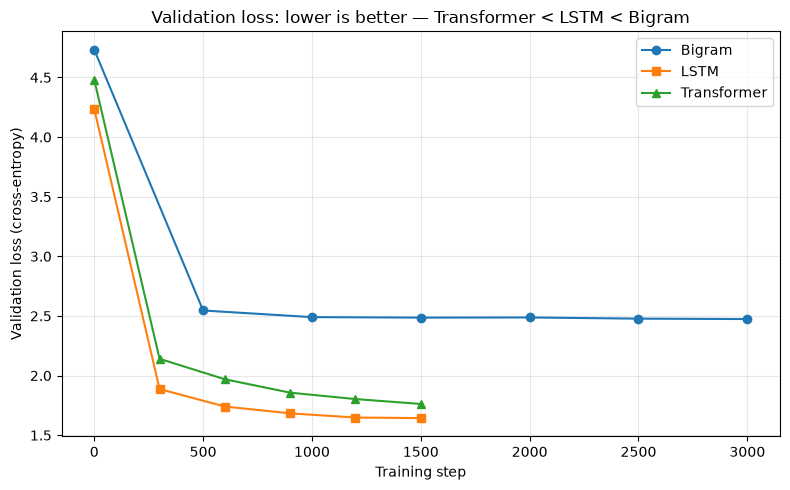

In [7]:
plt.figure(figsize=(8, 5))
for hist, label, style in [(bigram_hist, "Bigram", "o-"),
                           (lstm_hist, "LSTM", "s-"),
                           (tf_hist, "Transformer", "^-")]:
    steps = [h[0] for h in hist]
    val = [h[2] for h in hist]
    plt.plot(steps, val, style, label=label)
plt.xlabel("Training step")
plt.ylabel("Validation loss (cross-entropy)")
plt.title("Validation loss: lower is better — Transformer < LSTM < Bigram")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [8]:
print("=" * 70)
for name, sample in [("BIGRAM", bigram_sample), ("LSTM", lstm_sample), ("TRANSFORMER", tf_sample)]:
    print(f"\n########## {name} — generated sample ##########")
    print(sample)
    print("-" * 70)


########## BIGRAM — generated sample ##########
	Gressthy thalethopre ma
Laver-jeng aunteill halaron wis tllke andal, meas the or
Wh je ere? f we n wandow h intisttanss hof bue Shir astee y aven.
I mf cal T, me sulourd bay houtheachosargaule he Ton's inour Wh ppr at t ofor orily Hak, aldmindd: Kns ity ff s! pe tr iscken ientus amewacoou bowh hela ris eren? isushe Mo athy.
GNe, mor Pe wok'sonkilllofed t
SExed ct aves d thnrd cetrgdl, unou, sean I
----------------------------------------------------------------------

########## LSTM — generated sample ##########
	I, fair, whonem your love
Therefore, no look us loth? 'Not here. The English Sever lieve alcheap'd
These stolding and sounds! Blunt, thou still it is not, where it I all
groudge upon on prescue or liestudg
its on as remanning last towgue rebel,
Did drawn'd these Sarlish did name of Talbot, bair
Thus vilit om majesty to, if the Boringgroas! but yet we and four again
To go, my lord, and bent such a'
-----------------------------

## Section 6 — Written Reflection

*(Written from the actual run above. Numbers are from this experiment; re-running may vary slightly
because of random initialisation — update them if you re-run.)*

**Results recap:** Bigram val loss **2.47**, LSTM **1.64**, Transformer **1.76**; training time
Bigram **3.4 s**, LSTM **108.7 s**, Transformer **113.5 s**.

**Which model performed best?** On this small corpus the **LSTM** reached the **lowest validation
loss (1.64)**, narrowly ahead of the small **Transformer (1.76)**; both are far below the **Bigram
(2.47)**. Lower cross-entropy means higher probability assigned to the true next character.

**Which model trained fastest?** The **Bigram** by a wide margin (3.4 s) — it is only a lookup table.
The LSTM and Transformer took similar time (~109 s vs ~114 s) for the same number of steps.

**Which generated the most realistic text?** The **Bigram** output is plausible letter pairs but no
real words. The **LSTM** and **Transformer** both produce word-like, locally grammatical Shakespeare
pastiche; in this particular run the LSTM's sample was at least as coherent as the Transformer's.

**What did the transformer improve — and was the added complexity worth it *here*?** Conceptually,
self-attention lets every position attend **directly** to all earlier positions, removing the
recurrent information bottleneck. **But in this experiment the small 2-layer Transformer did not beat
the LSTM.** That is the key, honest finding: on only ~225K characters with a tiny model and 1,500
steps, the recurrence inductive bias of the LSTM is very competitive, and the Transformer's advantage
— which shows up with **more data, more layers, and longer training** — had not yet materialised. So
for *this* scale the extra complexity was **not clearly worth it**; the lesson is that transformers
are powerful *at scale*, not automatically at every size.

**What I learned about attention:** attention replaces "compress the whole past into one hidden vector"
(LSTM) with "look directly at whichever earlier tokens are relevant," which is more expressive for
long-range dependencies and, crucially, **parallelisable**. Its benefit over recurrence grows as data
and model size grow — exactly why it underpins large language models rather than tiny ones.

---

### Final reflection question

**After comparing bigram, non-transformer, and transformer models, what makes transformers powerful
for language modelling?**

Transformers are powerful because **self-attention gives every token direct, weighted access to every
other token in the context in a single, parallel step**, instead of squeezing the past through a
fixed-size recurrent state (LSTM) or ignoring it entirely (bigram). This removes the information
bottleneck and the vanishing-signal problem of RNNs and lets the model learn which earlier tokens
matter. My own experiment adds an important nuance: at tiny scale a well-tuned LSTM can match or beat a
small transformer — the transformer's real power is that attention **scales**, so with far more data
and parameters (and parallel training on hardware) it keeps improving where recurrence plateaus, which
is ultimately what makes it the backbone of modern large language models.